In [1]:
from astroML.datasets import generate_mu_z
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from astroML.linear_model import PolynomialRegression
from astroML.linear_model import BasisFunctionRegression
from astroML.linear_model import NadarayaWatson
from sklearn.model_selection import learning_curve

c:\Users\nicco\anaconda3\Lib\site-packages\astroML\linear_model\linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


## Time to get your hands dirty! Supernova distances and redshifts (part 1)

*(exam guidelines available [here](https://github.com/dgerosa/astrostatistics_bicocca_2026/blob/main/exams.md))*


Measuring the cosmological relationship between distance and redshift is at the heart of the entire field of cosmology and allowed, among other things, the discovery of dark energy! At high redshifts, this is done with Type Ia Supernova which are standard (or better, standardizable) candles.

Let's recall the definition of magnitude and the distance modulus (ah! the astronomers...)

$$
\mu = m-M =  5 \log_{10}\left(\frac{d_L}{\rm pc}\right) - 5
$$

Here is the Hubble diagram for Type Ia supernovae (which are standard candels). The lines show the predictions for cosmologies with varying amounts of Ωm and ΩΛ. The observed points all lie above the line for a universe with zero Λ. The lower panel, with the slope caused by the inverse square law taken out, shows the difference between the predictions more clearly and shows why a model with ΩΛ > 0 is favored. 

####  Tasks

- First, explore fitting this data with the tecniques we have seen.
- Start from linear regression and polynomial regression
- For the case of  polynomial regression, just fit many of them for now.
- Let's bet based on intuition! Which fit is the best?
- In what cases are you underfitting the data?
- In what cases are you overfitting the data?
- Now split the data into training and validation sets
- Implement a cross-validation procedure
- Pick the best!
- Does it agree with our bets?

#### OPTIONAL
- Repeat with Basis Function Regression and Kernel Regression
- Explore what happens when you change the number of datapoints and plot the resulting learning curves.

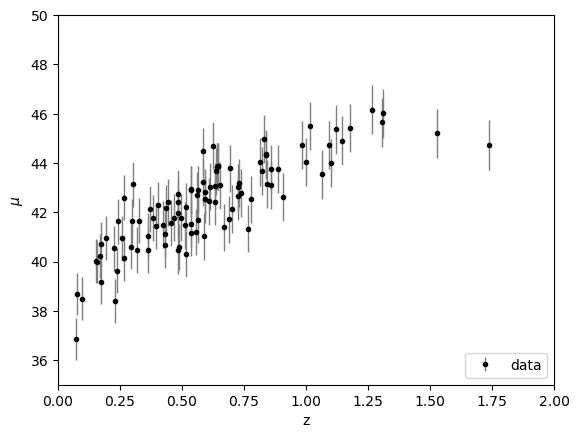

In [ ]:
z_sample, mu_sample, dmu = generate_mu_z(100, random_state=1234) # YOU CANNOT CHANGE THIS

plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50);

### Linear

In [6]:
linear = PolynomialRegression(1) # fit 3rd degree polynomial
linear.fit(z_sample.reshape(-1, 1), mu_sample, dmu)

x_grid = np.linspace(0, 2, 100)
y_pred = linear.predict(x_grid.reshape(-1, 1))

print(linear.coef_)

[39.48384602  4.76438865]


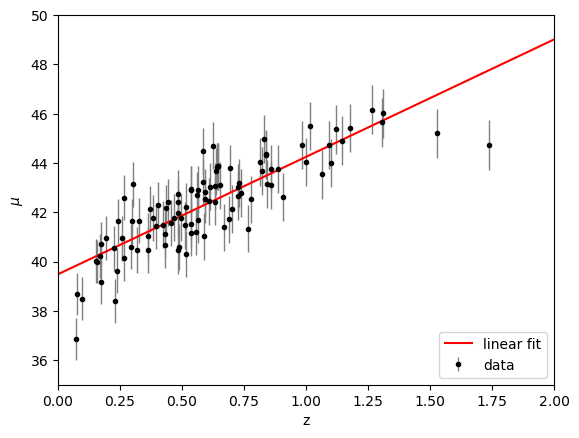

In [7]:
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.plot(x_grid, y_pred, '-r', label='linear fit')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50)
plt.show()

### Higher Order Plynomials

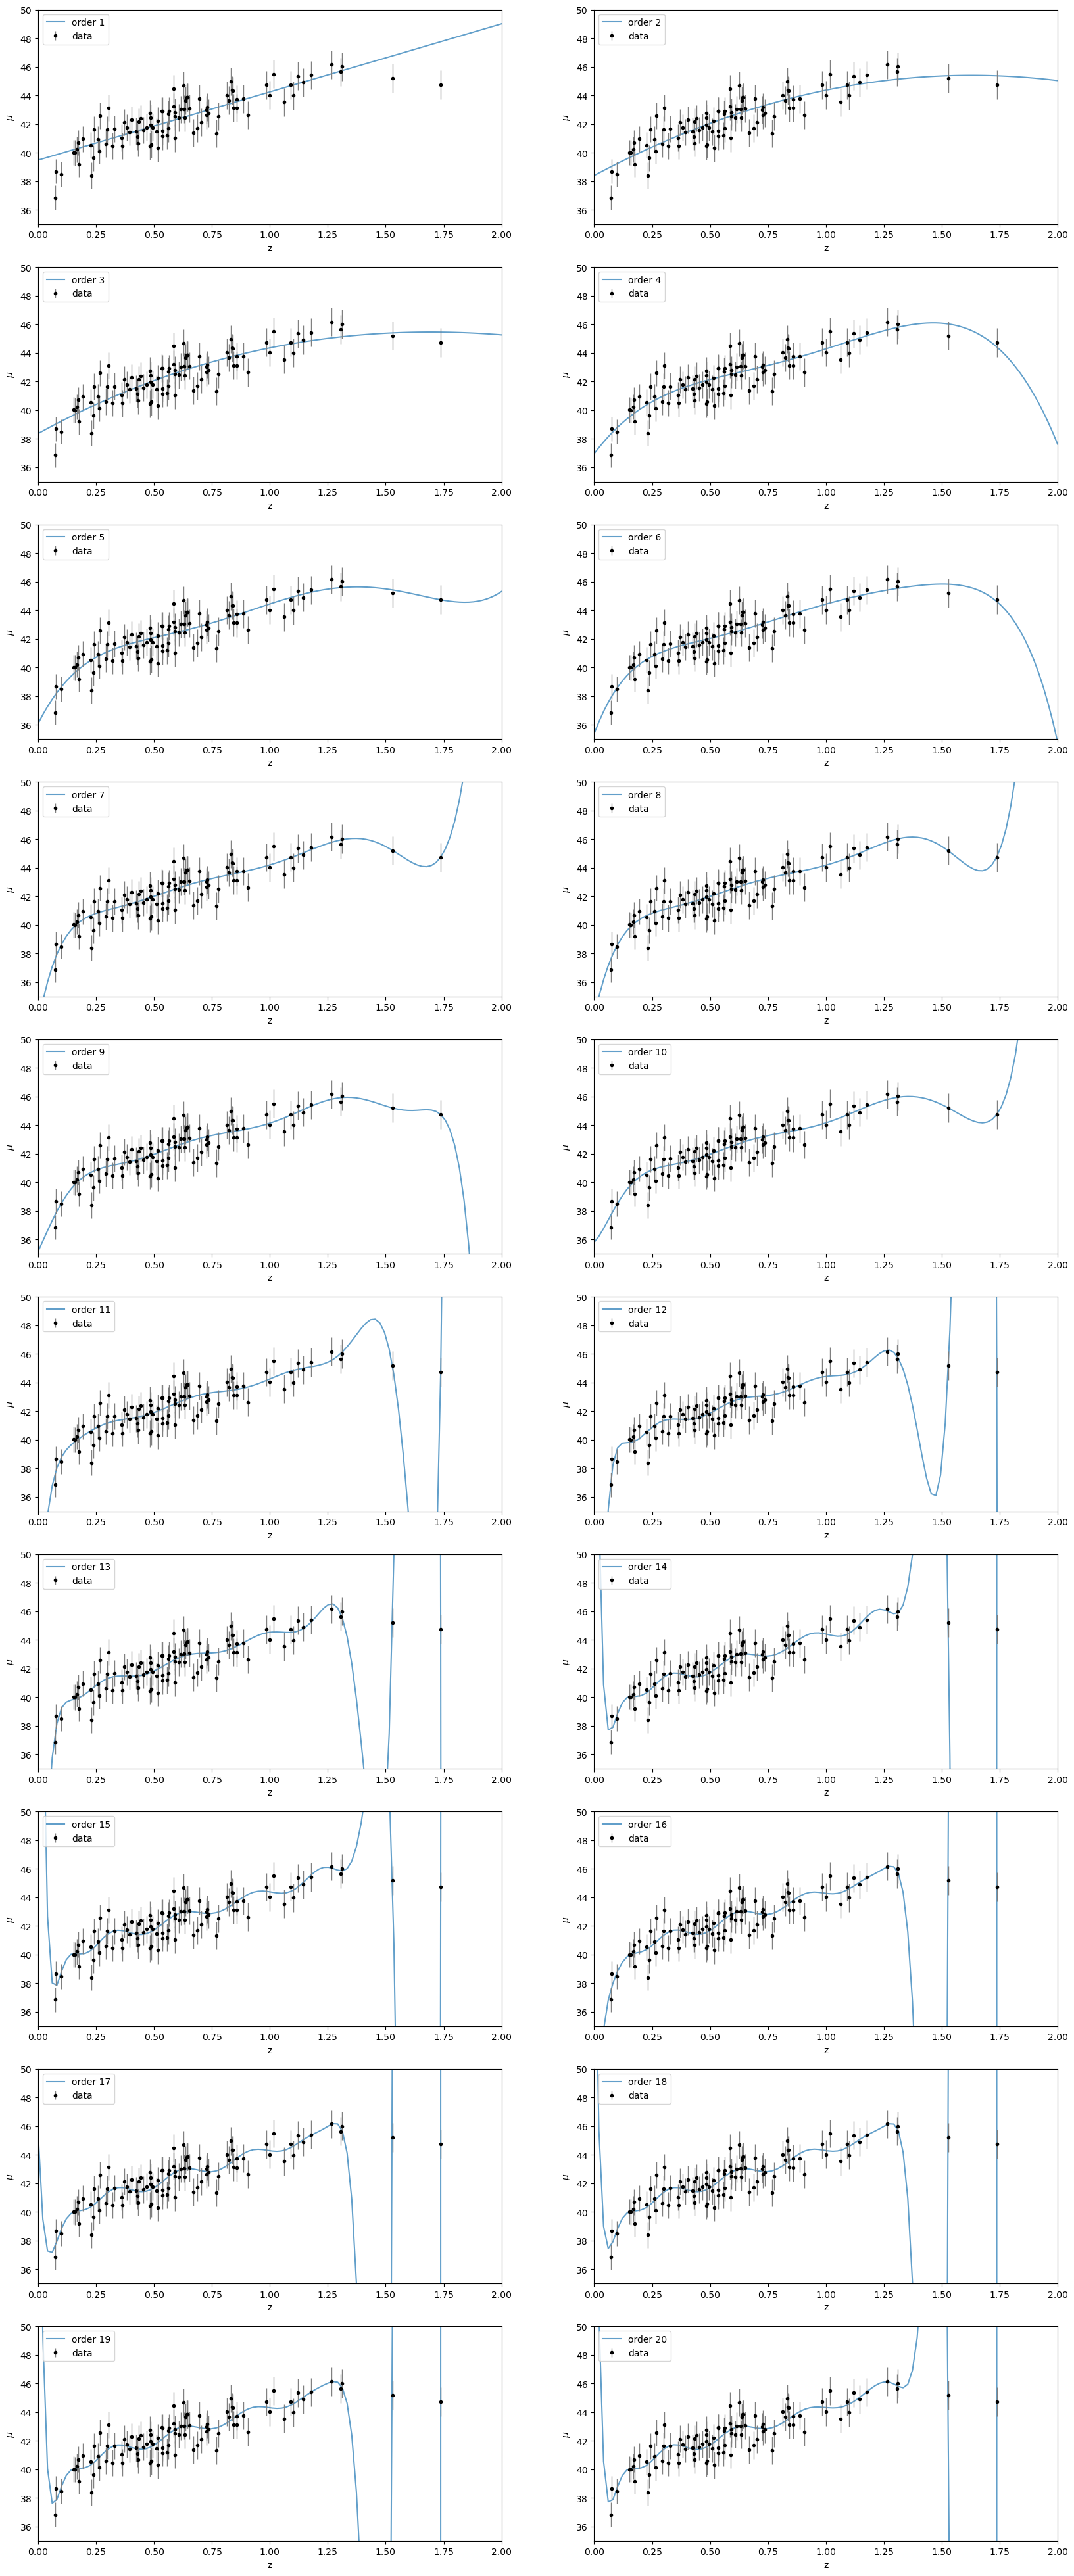

In [12]:
orders = 20
y_pred = np.zeros((orders, len(x_grid)))

figure, axes = plt.subplots(10, 2, figsize=(20, 50))


for i in range(1, orders + 1): 
    
    model = PolynomialRegression(i)
    model.fit(z_sample.reshape(-1, 1), mu_sample, dmu)
    y_pred[i-1] = model.predict(x_grid.reshape(-1, 1))
    axes[(i-1)//2, (i-1)%2].plot(x_grid, y_pred[i-1], alpha=0.7, label=f'order {i}')
    axes[(i-1)//2, (i-1)%2].errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
    axes[(i-1)//2, (i-1)%2].set_xlabel("z")
    axes[(i-1)//2, (i-1)%2].set_ylabel("$\mu$")
    axes[(i-1)//2, (i-1)%2].legend(loc='upper left')
    axes[(i-1)//2, (i-1)%2].set_xlim(0,2)
    axes[(i-1)//2, (i-1)%2].set_ylim(35,50)
plt.show()

It seems to me that just 1 is visually underfitting, while for $d>3$ we're overfitting, so I bet for something between 2 and 3. 

### Cross Validation

C:\Users\nicco\AppData\Local\Temp\ipykernel_27640\1732525375.py:10: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ".k" (-> color='k'). The keyword argument will take precedence.
  plt.errorbar(Xtest, ytest, yerr=dmu[test], fmt='.k', ecolor='gray', lw=1, label='Test Data', color='blue')
C:\Users\nicco\AppData\Local\Temp\ipykernel_27640\1732525375.py:11: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ".k" (-> color='k'). The keyword argument will take precedence.
  plt.errorbar(Xvalidation, yvalidation, yerr=dmu[validation], fmt='.k', ecolor='gray', lw=1, label='Validation Data', color='orange')


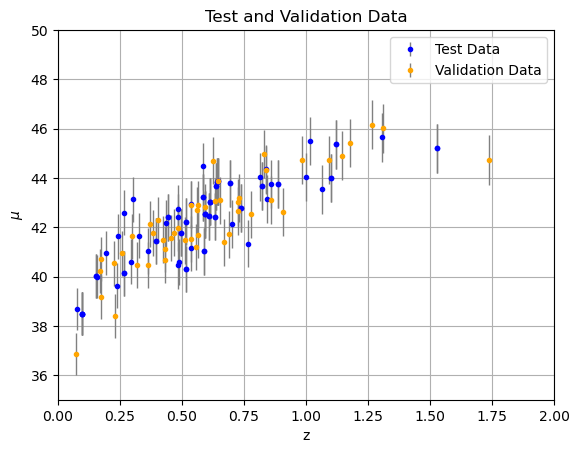

In [28]:
test = np.sort(np.random.choice(100, 80))
validation = np.setdiff1d(np.arange(100), test)

Xtest = z_sample[test].reshape(-1, 1)
ytest = mu_sample[test]

Xvalidation = z_sample[validation].reshape(-1, 1)
yvalidation = mu_sample[validation]

plt.errorbar(Xtest, ytest, yerr=dmu[test], fmt='.k', ecolor='gray', lw=1, label='Test Data', color='blue')
plt.errorbar(Xvalidation, yvalidation, yerr=dmu[validation], fmt='.k', ecolor='gray', lw=1, label='Validation Data', color='orange')
plt.xlabel('z')
plt.ylabel('$\mu$')
plt.title('Test and Validation Data')
plt.legend()
plt.xlim(0, 2)
plt.ylim(35, 50)
plt.grid()
plt.show()

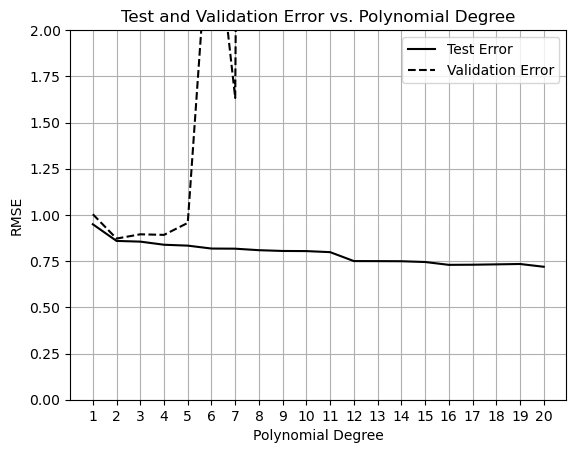

In [29]:
e_test = []
e_val = []

for i in range(1, orders + 1):
    model = PolynomialRegression(i)
    model.fit(Xtest, ytest, dmu[test])
    y_pred_test = model.predict(Xtest)
    y_pred_validation = model.predict(Xvalidation)
    
    e_test.append(np.sqrt(np.mean((y_pred_test - ytest)**2)))
    e_val.append(np.sqrt(np.mean((y_pred_validation - yvalidation)**2)))

plt.plot(range(1, orders + 1), e_test, '-k', label='Test Error')
plt.plot(range(1, orders + 1), e_val, '--k', label='Validation Error')
plt.xlabel('Polynomial Degree')
plt.ylabel('RMSE')
plt.title('Test and Validation Error vs. Polynomial Degree')
plt.legend()
plt.xticks(range(1, orders + 1))
plt.ylim(0, 2)
plt.grid()
plt.show()


It depends too much on the last few points, so I do the procedure 4 times and do the mean of the errors

In [34]:
grid = np.random.permutation(np.arange(100))
chunks = [0, 20, 40, 60, 80, 100]

e_test = []
e_val = []

for k in range(1, len(chunks)):
    test_idx = grid[chunks[k-1]:chunks[k]]
    val_idx = np.setdiff1d(np.arange(100), test_idx)
    
    Xtest = z_sample[test_idx].reshape(-1, 1)
    ytest = mu_sample[test_idx]
    
    Xval = z_sample[val_idx].reshape(-1, 1)
    yval = mu_sample[val_idx]
    
    print(f"Chunk {k}")
    
    e_chunk_test = []
    e_chunk_val = []
    
    for i in range(1, orders + 1):
        
        model = PolynomialRegression(i)  # Using a fixed degree for simplicity
        model.fit(Xtest, ytest, dmu[test_idx])
    
        y_pred_test = model.predict(Xtest)
        y_pred_val = model.predict(Xval)
    
        e_chunk_test.append(np.sqrt(np.mean((y_pred_test - ytest)**2)))
        e_chunk_val.append(np.sqrt(np.mean((y_pred_val - yval)**2)))
    
    e_test.append(e_chunk_test)
    e_val.append(e_chunk_val)

e_test = np.mean(e_test, axis=0)
e_val = np.mean(e_val, axis=0)

Chunk 1
Chunk 2
Chunk 3
Chunk 4
Chunk 5


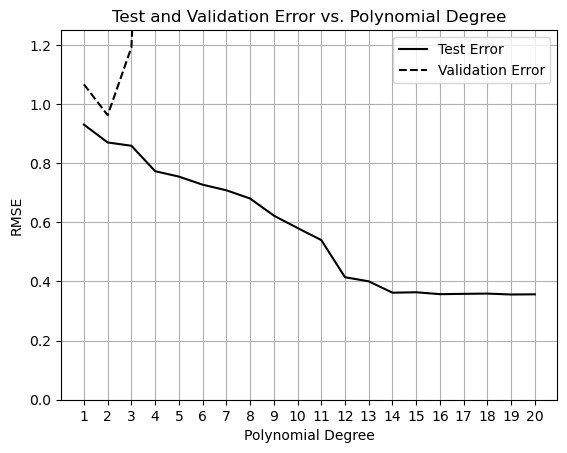

In [36]:
plt.plot(range(1, orders + 1), e_test, '-k', label='Test Error')
plt.plot(range(1, orders + 1), e_val, '--k', label='Validation Error')
plt.xlabel('Polynomial Degree')
plt.ylabel('RMSE')
plt.title('Test and Validation Error vs. Polynomial Degree')
plt.legend()
plt.xticks(range(1, orders + 1))
plt.ylim(0, 1.25)
plt.grid()
plt.show()

This seems like a good result

### Basic funcrion regression

#### Test

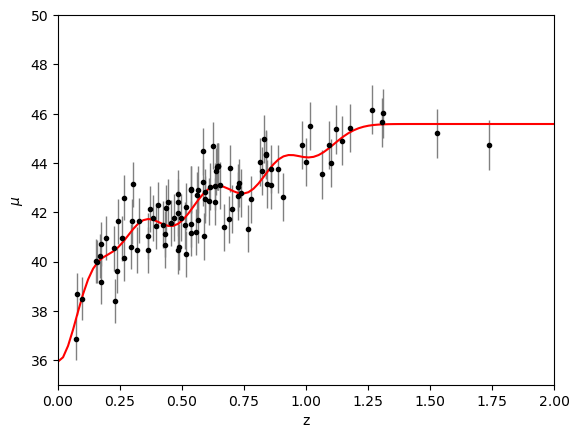

In [77]:
# mean positions of the 10 Gaussians in the model
X_gridtest = np.linspace(0,1,10)[:, None]
# widths of these Gaussians
sigma_test = 0.1

gaussian = BasisFunctionRegression('gaussian', mu=X_gridtest, sigma=sigma_test)

gaussian.fit(z_sample.reshape(-1, 1), mu_sample, dmu)
y_pred = gaussian.predict(x_grid.reshape(-1, 1))

plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.plot(x_grid, y_pred, label='Predicted Function', color='red')
plt.xlabel('z')
plt.ylabel('$\mu$')
plt.xlim(0, 2)
plt.ylim(35, 50)
plt.show()

#### Learning Curve

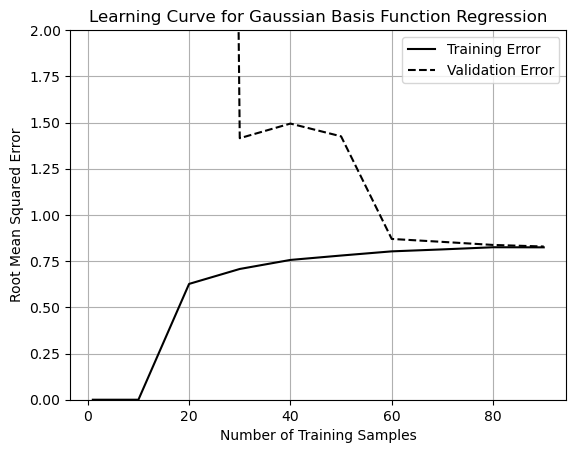

In [92]:
gaussian = BasisFunctionRegression('gaussian', mu=X_gridtest, sigma=sigma_test)
size = [1, 10, 20, 30, 40, 50, 60, 70, 80, 90]

e_train = []
e_val = []

for k in range(10):
    grid = np.random.permutation(np.arange(100))
    
    e_size_train = []
    e_size_val = []
    
    for s in size:
        z_train = z_sample[grid[:s]].reshape(-1, 1)
        mu_train = mu_sample[grid[:s]]
        gaussian.fit(z_train, mu_train, dmu[grid[:s]])
        e_size_train.append(np.sqrt(np.mean((gaussian.predict(z_train) - mu_train)**2)))
        e_size_val.append(np.sqrt(np.mean((gaussian.predict(z_sample.reshape(-1, 1)) - mu_sample)**2)))
    e_train.append(e_size_train)
    e_val.append(e_size_val)
    
e_train = np.mean(e_train, axis=0)
e_val = np.mean(e_val, axis=0)

plt.plot(size, e_train, '-k', label='Training Error')
plt.plot(size, e_val, '--k', label='Validation Error')
plt.xlabel('Number of Training Samples')
plt.ylabel('Root Mean Squared Error')
plt.ylim(0, 2)
plt.grid()
plt.title('Learning Curve for Gaussian Basis Function Regression')
plt.legend()
plt.show()
    

Clearly gaussians BasicFunctionRegression performs pourly with few data points

### Kernel Regression

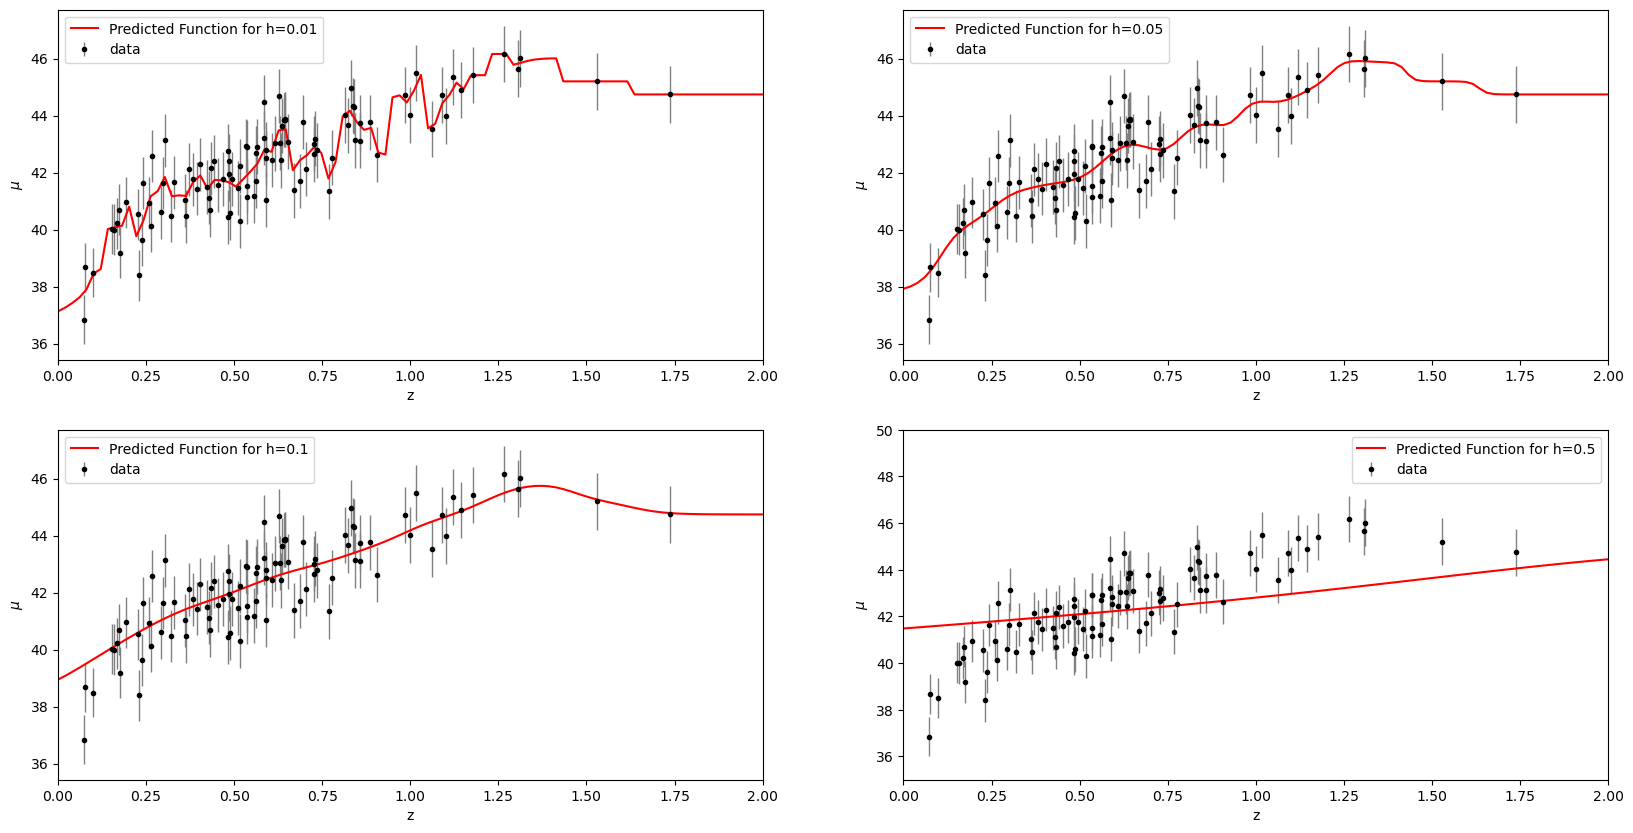

In [64]:
h = [0.01, 0.05, 0.1, 0.5]

kernel = [NadarayaWatson(kernel='gaussian', h=h_val) for h_val in h]

for k in kernel:
    k.fit(z_sample.reshape(-1, 1), mu_sample, dmu)

figures, axes = plt.subplots(2, 2, figsize=(20, 10))

for i, k in enumerate(kernel):
    y_pred = k.predict(x_grid.reshape(-1, 1))
    plt.subplot(2, 2, i + 1)
    plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
    plt.plot(x_grid, y_pred, label=f'Predicted Function for h={h[i]}', color='red')
    plt.xlabel('z')
    plt.ylabel('$\mu$')
    plt.xlim(0, 2)
    plt.legend()
plt.ylim(35, 50)
plt.show()

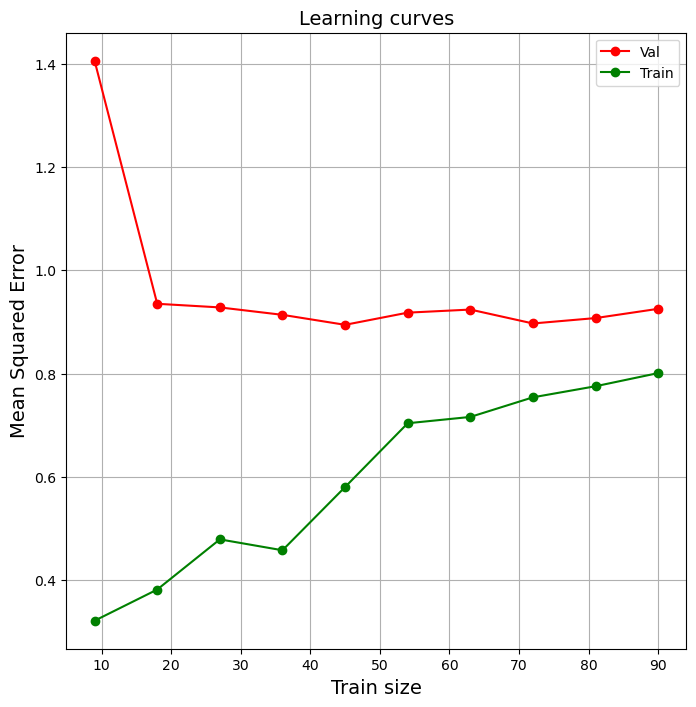

In [67]:
train_sizes, train_scores_linreg, test_scores_linreg = \
    learning_curve(kernel[2], z_sample.reshape(-1, 1), mu_sample, train_sizes=np.linspace(0.1, 1, 10), \
    scoring="neg_mean_squared_error", cv=10)
    
fig = plt.figure(figsize=(8, 8))

plt.plot(train_sizes, -test_scores_linreg.mean(1), 'o-', color="r", label="Val")
plt.plot(train_sizes, -train_scores_linreg.mean(1), 'o-', color="g", label="Train")
                   
plt.xlabel("Train size",fontsize=14)
plt.ylabel("Mean Squared Error",fontsize=14)
plt.title('Learning curves',fontsize=14)
plt.legend(loc="best")
plt.grid()
plt.show()